<a href="https://colab.research.google.com/github/hafizzx/python-projects/blob/main/Logestic_regression_by_percepron_trick.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from sklearn.datasets import make_classification
import numpy as np
X, y = make_classification(n_samples=100, n_features=2, n_informative=1,n_redundant=0,
                           n_classes=2, n_clusters_per_class=1, random_state=41,hypercube=False,class_sep=10)

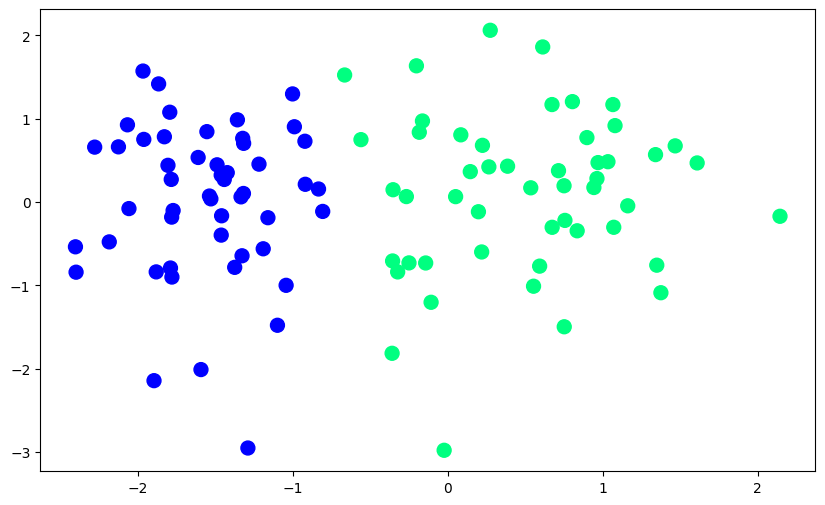

In [2]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

In [3]:
def step(z):
    return 1 if z>0 else 0

In [4]:
def perceptron(X,y):

    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1

    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]

    return weights[0],weights[1:]

In [11]:
intercept_ = perceptron(X,y)[0]

In [14]:
coef_ = perceptron(X,y)[1]

In [15]:
print(intercept_)
print(coef_)

0.9
[1.29356975 0.19032516]


**y = mx+c , Ax+By+C = 0m = -A/B b = -C/B**

In [16]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

In [17]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + b

(-3.0, 2.0)

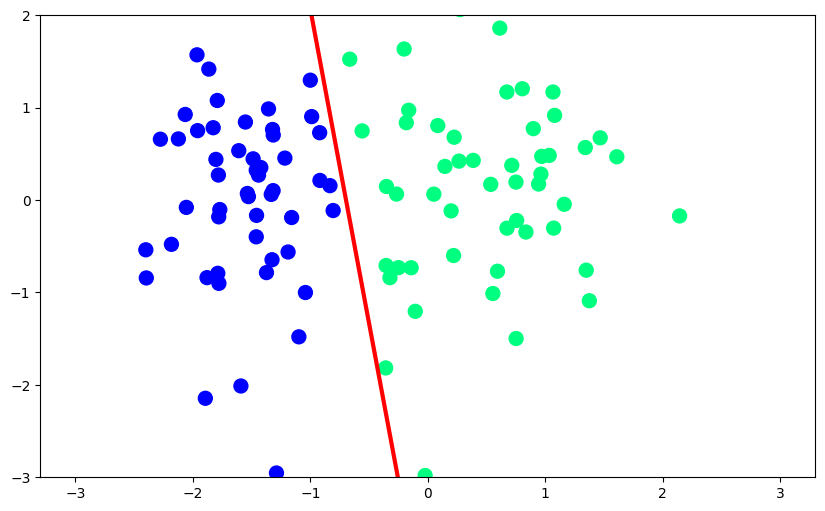

In [18]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

In [19]:
def perceptron(X,y):

    m = []
    b = []

    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1

    for i in range(200):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]

        m.append(-(weights[1]/weights[2]))
        b.append(-(weights[0]/weights[2]))

    return m,b

In [20]:
m,b = perceptron(X,y)

In [21]:
%matplotlib notebook
from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

fig, ax = plt.subplots(figsize=(9, 5))

x_i = np.arange(-3, 3, 0.1)

ax.scatter(X[:, 0], X[:, 1], c=y, cmap='winter', s=100)

line, = ax.plot(x_i, x_i * m[0] + b[0], 'r-', linewidth=2)

ax.set_ylim(-3, 3)

def update(i):
    line.set_ydata(x_i * m[i] + b[i])
    ax.set_xlabel(f'Epoch {i + 1}')
    return line,

anim = FuncAnimation(
    fig,
    update,
    frames=min(200, len(m), len(b)),
    interval=100,
    blit=True
)

display(HTML(anim.to_jshtml()))
plt.close(fig)

<IPython.core.display.Javascript object>

AttributeError: 'NoneType' object has no attribute 'remove_callback'